This notebook shows the link-level models of 3GPP TR 38.811 at work: `TDL`, the tapped delay line models NTN-TDL-A to NTN-TDL-D of its clause 6.9.2, and `CDL`, the clustered delay line models NTN-CDL-A to NTN-CDL-D of its clause 6.9.1. Its five sections show the models and the parameters that `openntn.utils.link_level_parameters` returns for them (section 1), the Doppler shift due to the motion of the satellite (section 2), its pre-compensation in the frequency and in the time domain (section 3), the block error rates of an OFDM link over NTN-TDL-A to NTN-TDL-D (section 4) and the rank of the MIMO channel of `CDL` (section 5).

The link of sections 3 and 4 builds on two Sionna tutorials: "Discover Sionna", an end-to-end model with OFDM and the 5G LDPC code over Sionna's TDL-A, and "MIMO OFDM Transmissions over the CDL Channel Model", which models the channel in the frequency and in the time domain. The file `docs/model.md` of the repository describes how the models read the clauses, in its section "The link-level models NTN-TDL and NTN-CDL".

First, we import all necessary libraries. The cell also sets the device, the precision, the seed and the mode, from the environment variable `OPENNTN_NOTEBOOK_MODE`: unset, sections 3 and 4 load the results of the full run from the file `link_level_models_results.npz` and plot them; `full`, they compute them with the parameters of this notebook and write the file (about 29 minutes on a laptop CPU); `reduced`, they compute 3 points with 2 iterations each, with which the continuous integration of OpenNTN runs the notebook, and write no file. Sections 1, 2 and 5 compute their results in every mode, section 5 with fewer examples in the reduced mode.

In [1]:
#
# SPDX-FileCopyrightText: Copyright (c) 2021-2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
# SPDX-License-Identifier: Apache-2.0
#
# Modified by the Dept. of Communications Engineering of the University of Bremen.
# The code is based on implementations provided by the NVIDIA CORPORATION & AFFILIATES
# in Sionna.
#

import datetime
import importlib.metadata
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

import sionna
import sionna.phy
from sionna.phy import Block
from sionna.phy.channel import (ApplyTimeChannel, OFDMChannel, cir_to_ofdm_channel,
                                cir_to_time_channel, subcarrier_frequencies,
                                time_lag_discrete_time_channel)
from sionna.phy.channel.tr38901 import CDL as SionnaCDL
from sionna.phy.channel.tr38901 import AntennaArray as SionnaAntennaArray
from sionna.phy.fec.ldpc import LDPC5GDecoder, LDPC5GEncoder
from sionna.phy.mapping import BinarySource, Demapper, Mapper
from sionna.phy.mimo import StreamManagement
from sionna.phy.ofdm import (LMMSEEqualizer, LSChannelEstimator, OFDMDemodulator,
                             OFDMModulator, RemoveNulledSubcarriers, ResourceGrid,
                             ResourceGridMapper)
from sionna.phy.utils import ebnodb2no, sim_ber

import openntn
from openntn import CDL, TDL, AntennaArray
from openntn.utils import link_level_parameters

# The device of the models and the antennas: a GPU if one is visible, otherwise the CPU
device = sionna.phy.config.device
# Single precision, and a fixed seed, so that every run gives the same results
sionna.phy.config.precision = "single"
seed = 42
sionna.phy.config.seed = seed

# The mode: unset, the results of sections 3 and 4 are loaded from the results file;
# "full", they are computed and written to it; "reduced", a few points are computed
mode = os.environ.get("OPENNTN_NOTEBOOK_MODE")
if mode not in (None, "full", "reduced"):
    raise ValueError(f"OPENNTN_NOTEBOOK_MODE must be unset, 'full' or 'reduced', not {mode!r}")
results_file = "link_level_models_results.npz"
print(f"Device {device}, precision {sionna.phy.config.precision}, mode {mode or 'unset'}")

Device cpu, precision single, mode full


## 1. The models and their parameters

`TDL` takes the normalized delays and the powers of TR 38.811, Tables 6.9.2-1 to 6.9.2-4, which are given at the reference elevation angle of 50 degrees: NTN-TDL-A and NTN-TDL-B for NLOS links, NTN-TDL-C and NTN-TDL-D for LOS links, whose first tap adds a specular path to its Rayleigh fading. The power delay profile is normalized to a total power of one, the specular path included. The next cell prints, for each model, the delays of its taps divided by the RMS delay spread and their powers in dB, with the first tap of NTN-TDL-C and NTN-TDL-D split into its specular path and its Rayleigh part, and draws them. The property `k_factor` is the K-factor of TR 38.901, eq. (7.7.6-2), the power of the specular path over that of all Rayleigh taps, in linear scale; the cell prints it in dB, the unit of the argument `k_factor`, with which a desired K-factor replaces it.

NTN-TDL-A: 3 taps
  Rayleigh tap     delay  0.0000  power   -1.95 dB
  Rayleigh tap     delay  1.0811  power   -6.62 dB
  Rayleigh tap     delay  2.8416  power   -8.43 dB
NTN-TDL-B: 4 taps
  Rayleigh tap     delay  0.0000  power   -3.16 dB
  Rayleigh tap     delay  0.7249  power   -5.13 dB
  Rayleigh tap     delay  0.7410  power   -7.49 dB
  Rayleigh tap     delay  5.7392  power  -15.07 dB
NTN-TDL-C: 2 taps
  specular path    delay  0.0000  power   -0.41 dB
  Rayleigh tap     delay  0.0000  power  -10.64 dB
  Rayleigh tap     delay 14.8124  power  -23.39 dB
  K-factor 10.000 dB
NTN-TDL-D: 3 taps
  specular path    delay  0.0000  power   -0.79 dB
  Rayleigh tap     delay  0.0000  power  -12.50 dB
  Rayleigh tap     delay  0.5596  power  -10.39 dB
  Rayleigh tap     delay  7.3340  power  -17.28 dB
  K-factor 7.000 dB


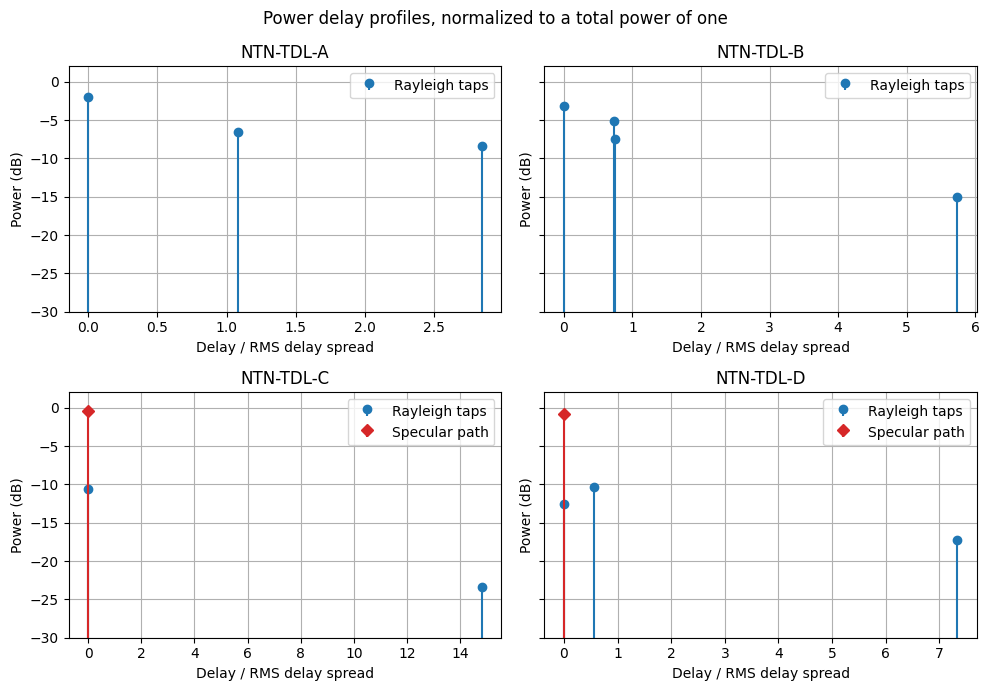

In [2]:
sionna.phy.config.seed = seed

# The four models at 2 GHz, for a satellite at 600 km seen at 50 degrees. The delay
# spread scales the delays only; they are printed divided by it.
profiles = {}
for name in "ABCD":
    tdl = TDL(name, 100e-9, 2e9, 50.0, 600e3)
    delays = (tdl.delays / tdl.delay_spread).cpu().numpy()
    powers = tdl.mean_powers.cpu().numpy()
    los_power = None
    print(f"NTN-TDL-{name}: {tdl.num_clusters} taps")
    if tdl.los:
        # The first tap of a LOS model: the specular path and the Rayleigh part
        los_power = float(tdl.mean_power_los)
        powers[0] -= los_power
        print(f"  specular path    delay {0.0:7.4f}  power {10 * np.log10(los_power):7.2f} dB")
    for delay, power in zip(delays, powers):
        print(f"  Rayleigh tap     delay {delay:7.4f}  power {10 * np.log10(power):7.2f} dB")
    if tdl.los:
        # The property is linear, the argument k_factor in dB
        print(f"  K-factor {10 * np.log10(float(tdl.k_factor)):.3f} dB")
    profiles[name] = (delays, powers, los_power)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
for ax, (name, (delays, powers, los_power)) in zip(axes.flat, profiles.items()):
    ax.stem(delays, 10 * np.log10(powers), bottom=-30.0, basefmt=" ",
            label="Rayleigh taps")
    if los_power is not None:
        ax.stem([0.0], [10 * np.log10(los_power)], bottom=-30.0, linefmt="C3-",
                markerfmt="C3D", basefmt=" ", label="Specular path")
    ax.set_title(f"NTN-TDL-{name}")
    ax.set_xlabel("Delay / RMS delay spread")
    ax.set_ylabel("Power (dB)")
    ax.set_ylim(-30.0, 2.0)
    ax.grid(True)
    ax.legend()
fig.suptitle("Power delay profiles, normalized to a total power of one")
fig.tight_layout()
plt.show()

The function `link_level_parameters` of `openntn.utils` returns suitable values of the arguments `delay_spread`, `angular_spreads` and `k_factor` of `TDL` and `CDL` for a scenario, a carrier frequency, an elevation angle and a link state, as clause 6.9.1 determines suitable values from the channel model parameters of clause 6.7.2: the medians of the delay spread, the ASA and the ZSA and the mean K-factor of TR 38.811, Tables 6.7.2-1a to 6.7.2-6b, at the reference elevation angle of the tables nearest to that of the link. The next cell evaluates it at the reference elevation angles from 10 to 90 degrees for the dense urban ("dur"), urban ("urb") and suburban ("sur") scenarios, in the S band at 2 GHz and in the Ka band at 20 GHz, for LOS and NLOS links, prints the values at 50 degrees and draws them all.

At 50 degrees: delay spread, ASA, ZSA and, for LOS links, the K-factor
dense urban,  S band, LOS :   12.303 ns    5.248 deg  26.9153 deg   7.40 dB
dense urban,  S band, NLOS:   45.709 ns   30.200 deg  27.5423 deg
dense urban, Ka band, LOS :    7.413 ns    2.291 deg  26.3027 deg   9.20 dB
dense urban, Ka band, NLOS:   38.019 ns   25.119 deg  25.1189 deg
      urban,  S band, LOS :    4.266 ns    0.851 deg   1.8621 deg   6.52 dB
      urban,  S band, NLOS:   10.233 ns    4.786 deg  19.9526 deg
      urban, Ka band, LOS :    3.311 ns    0.263 deg   0.6166 deg   7.42 dB
      urban, Ka band, NLOS:    8.318 ns    3.631 deg  13.8038 deg
   suburban,  S band, LOS :    1.905 ns    0.263 deg   0.0282 deg  21.60 dB
   suburban,  S band, NLOS:    2.291 ns    1.905 deg   0.0158 deg
   suburban, Ka band, LOS :    2.884 ns    0.646 deg  33.8844 deg   7.50 dB
   suburban, Ka band, NLOS:   10.471 ns    9.550 deg  19.4984 deg


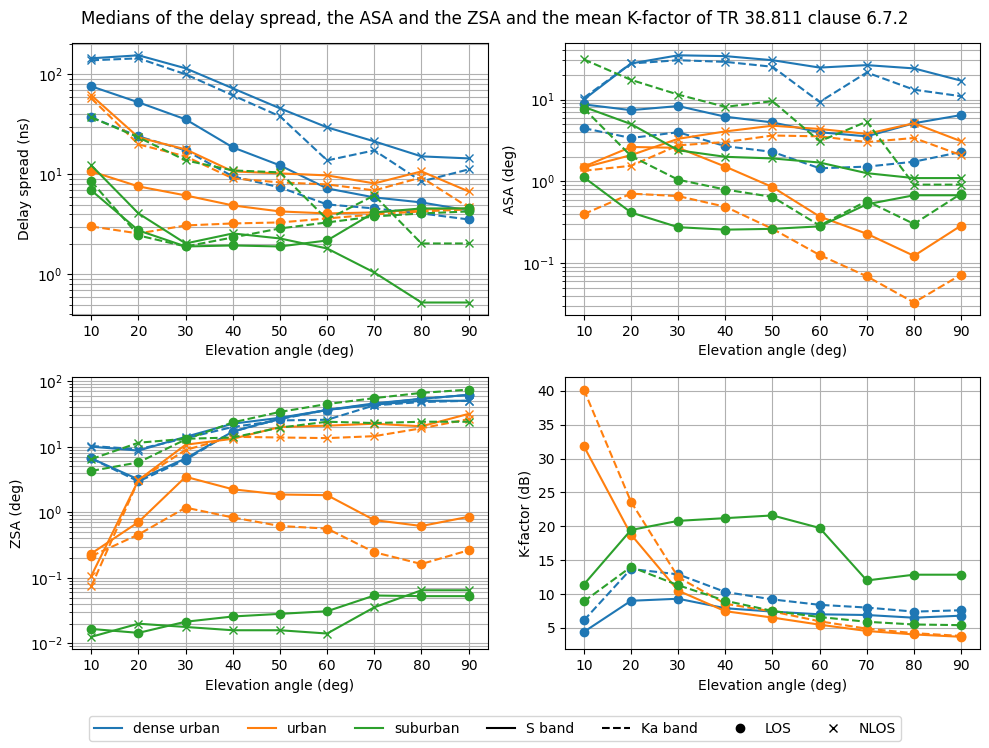

In [3]:
sionna.phy.config.seed = seed

scenarios = {"dur": "dense urban", "urb": "urban", "sur": "suburban"}
bands = {"S": 2e9, "Ka": 20e9}
reference_angles = np.arange(10.0, 90.5, 10.0)
parameters = {}
for scenario in scenarios:
    for band, carrier_frequency in bands.items():
        for los in (True, False):
            values = [link_level_parameters(scenario, carrier_frequency, angle, los=los)
                      for angle in reference_angles]
            parameters[(scenario, band, los)] = {
                "ds": np.array([v[0] for v in values]),
                "asa": np.array([v[1][0] for v in values]),
                "zsa": np.array([v[1][1] for v in values]),
                # The NLOS tables give no K-factor: None
                "k": np.array([np.nan if v[2] is None else v[2] for v in values])}

at_50 = list(reference_angles).index(50.0)
print("At 50 degrees: delay spread, ASA, ZSA and, for LOS links, the K-factor")
for (scenario, band, los), p in parameters.items():
    line = (f"{scenarios[scenario]:>11}, {band:>2} band, {'LOS ' if los else 'NLOS'}: "
            f"{p['ds'][at_50] * 1e9:8.3f} ns {p['asa'][at_50]:8.3f} deg "
            f"{p['zsa'][at_50]:8.4f} deg")
    if los:
        line += f" {p['k'][at_50]:6.2f} dB"
    print(line)

colors = {"dur": "C0", "urb": "C1", "sur": "C2"}
styles = {"S": "-", "Ka": "--"}
markers = {True: "o", False: "x"}
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
quantities = [("ds", 1e9, "Delay spread (ns)", True), ("asa", 1.0, "ASA (deg)", True),
              ("zsa", 1.0, "ZSA (deg)", True), ("k", 1.0, "K-factor (dB)", False)]
for ax, (key, scale, ylabel, logarithmic) in zip(axes.flat, quantities):
    for (scenario, band, los), p in parameters.items():
        if key == "k" and not los:
            continue
        ax.plot(reference_angles, p[key] * scale, color=colors[scenario],
                linestyle=styles[band], marker=markers[los])
    if logarithmic:
        ax.set_yscale("log")
    ax.set_xlabel("Elevation angle (deg)")
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both")
handles = ([plt.Line2D([], [], color=c, label=scenarios[s]) for s, c in colors.items()]
           + [plt.Line2D([], [], color="k", linestyle=st, label=f"{b} band")
              for b, st in styles.items()]
           + [plt.Line2D([], [], color="k", linestyle="", marker=m,
                         label="LOS" if los else "NLOS") for los, m in markers.items()])
fig.legend(handles=handles, loc="lower center", ncol=7)
fig.suptitle("Medians of the delay spread, the ASA and the ZSA and the mean K-factor "
             "of TR 38.811 clause 6.7.2")
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

NTN-TDL-A has 3 taps, NTN-TDL-B 4, NTN-TDL-C 2 and NTN-TDL-D 3. The specular path of NTN-TDL-C carries -0.41 dB of the total power and the Rayleigh part of its first tap -10.64 dB, those of NTN-TDL-D -0.79 dB and -12.50 dB; their K-factors, 10.000 dB and 7.000 dB, are those of the tables. The last tap of NTN-TDL-C, at 14.8124 times the delay spread, carries -23.39 dB.

The tables of clause 6.7.2 give the means of the decadic logarithms of the delay spread, the ASA and the ZSA, so that their medians are 10 to the power of these means, and the mean of the K-factor in dB. A median or a mean is one choice of a suitable value; another percentile of the distributions is another. The NLOS tables give no K-factor: the function returns `None` for NLOS links, which `TDL` and `CDL` read as the K-factor of their tables, and the figure has no NLOS curves of the K-factor. At 50 degrees in the S band, the delay spreads range from 1.905 ns for suburban LOS links to 45.709 ns for dense urban NLOS links, and the K-factors from 6.52 dB for urban to 21.60 dB for suburban LOS links. Sections 3 and 4 take the values of the dense urban scenario at 2 GHz and 50 degrees, the delay spread 12.303 ns and the K-factor 7.40 dB of LOS links and the delay spread 45.709 ns of NLOS links, and section 5 its delay spreads.

## 2. The Doppler shift of the satellite

By default, `TDL` and `CDL` apply the Doppler shift due to the motion of the satellite of clause 6.9.2 to all taps, clusters and rays,

$$f_{d,\text{shift}} = \frac{v_\text{sat}}{c} \frac{R}{R+h} \cos(\alpha) f_c,$$

with the speed $v_\text{sat}$ of a circular orbit at the height $h$ of the satellite, the radius $R$ of the Earth, the elevation angle $\alpha$ of the link and the carrier frequency $f_c$. It is the largest shift, that of an approaching satellite seen from a UT in its orbital plane, and 0 for a geostationary satellite and for an aerial platform. The property `doppler_shift` gives it; the argument `doppler_shift` replaces it, with 0 for a link whose terminal pre-compensates the shift, as TS 38.101-5 sets the Doppler shift of the satellite motion to zero for the performance requirements of its Table 8.2.1.2.2.1.1-3 (its clause A.4.4). The next cell prints and draws the shift over the elevation angle at 600 km and 1200 km, at 2 GHz and 20 GHz, in kHz and in subcarrier spacings, 15 kHz at 2 GHz and 120 kHz at 20 GHz, and the shift of a geostationary satellite at 35 786 km.

Doppler shift of the satellite in kHz, and in subcarrier spacings
2 GHz, 600 km:
    10 deg:   45.40 kHz,  3.03 spacings
    30 deg:   39.93 kHz,  2.66 spacings
    50 deg:   29.63 kHz,  1.98 spacings
    70 deg:   15.77 kHz,  1.05 spacings
    90 deg:    0.00 kHz,  0.00 spacings
2 GHz, 1200 km:
    10 deg:   40.11 kHz,  2.67 spacings
    30 deg:   35.28 kHz,  2.35 spacings
    50 deg:   26.18 kHz,  1.75 spacings
    70 deg:   13.93 kHz,  0.93 spacings
    90 deg:    0.00 kHz,  0.00 spacings
20 GHz, 600 km:
    10 deg:  454.03 kHz,  3.78 spacings
    30 deg:  399.27 kHz,  3.33 spacings
    50 deg:  296.35 kHz,  2.47 spacings
    70 deg:  157.68 kHz,  1.31 spacings
    90 deg:    0.00 kHz,  0.00 spacings
20 GHz, 1200 km:
    10 deg:  401.14 kHz,  3.34 spacings
    30 deg:  352.76 kHz,  2.94 spacings
    50 deg:  261.83 kHz,  2.18 spacings
    70 deg:  139.32 kHz,  1.16 spacings
    90 deg:    0.00 kHz,  0.00 spacings
2 GHz, 35786 km, 50 deg: 0.0 Hz


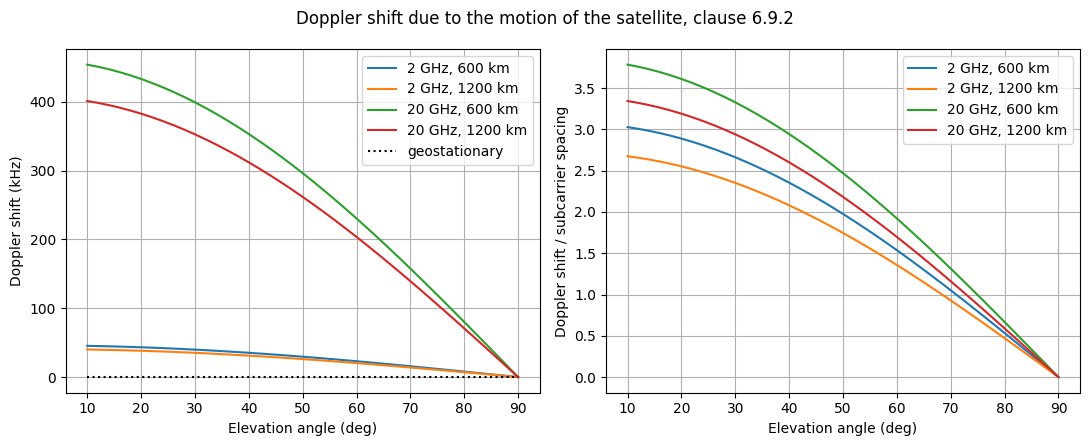

In [4]:
sionna.phy.config.seed = seed

spacings = {2e9: 15e3, 20e9: 120e3}
heights = [600e3, 1200e3]
angles = np.arange(10.0, 90.5, 2.0)
shifts = {}
for carrier_frequency in spacings:
    for height in heights:
        shifts[(carrier_frequency, height)] = np.array(
            [TDL("A", 100e-9, carrier_frequency, angle, height).doppler_shift
             for angle in angles])
geostationary_shift = TDL("A", 100e-9, 2e9, 50.0, 35786e3).doppler_shift

print("Doppler shift of the satellite in kHz, and in subcarrier spacings")
for (carrier_frequency, height), values in shifts.items():
    print(f"{carrier_frequency / 1e9:.0f} GHz, {height / 1e3:.0f} km:")
    for angle in (10.0, 30.0, 50.0, 70.0, 90.0):
        value = values[list(angles).index(angle)]
        print(f"  {angle:4.0f} deg: {value / 1e3:7.2f} kHz, "
              f"{value / spacings[carrier_frequency]:5.2f} spacings")
print(f"2 GHz, 35786 km, 50 deg: {geostationary_shift:.1f} Hz")

fig, (ax_khz, ax_spacings) = plt.subplots(1, 2, figsize=(11, 4.5))
for (carrier_frequency, height), values in shifts.items():
    label = f"{carrier_frequency / 1e9:.0f} GHz, {height / 1e3:.0f} km"
    ax_khz.plot(angles, values / 1e3, label=label)
    ax_spacings.plot(angles, values / spacings[carrier_frequency], label=label)
ax_khz.plot(angles, np.full(angles.shape, geostationary_shift / 1e3), "k:",
            label="geostationary")
ax_khz.set_ylabel("Doppler shift (kHz)")
ax_spacings.set_ylabel("Doppler shift / subcarrier spacing")
for ax in (ax_khz, ax_spacings):
    ax.set_xlabel("Elevation angle (deg)")
    ax.grid(True)
    ax.legend()
fig.suptitle("Doppler shift due to the motion of the satellite, clause 6.9.2")
fig.tight_layout()
plt.show()

The shift is contained in the path coefficients at every sample. The link of sections 3 and 4 transmits 14 OFDM symbols of 15 kHz on 52 resource blocks, 624 subcarriers, with a cyclic prefix of 44 samples. The next cell draws the phase of the path coefficient of the first tap of NTN-TDL-C, for a UT at rest, sampled once per OFDM symbol, as a channel in the frequency domain samples it: with the shift at 600 km, 50 degrees and 2 GHz, and with `doppler_shift=0`, both from the same seed.

Shift 29634.973 Hz, OFDM symbol with its cyclic prefix 71.368 µs: 2.1150 turns of the phase per symbol, a step of 0.7224 rad between the samples


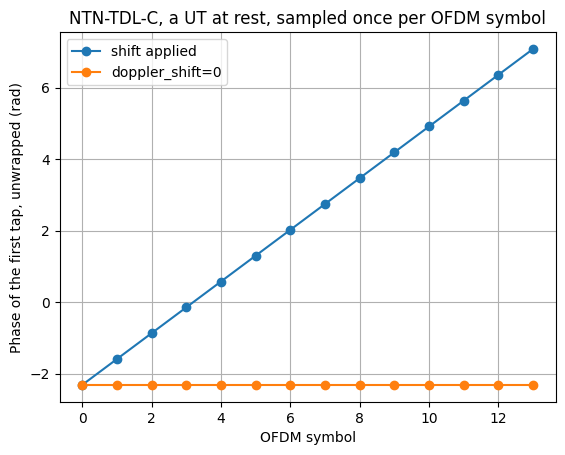

In [5]:
# The numerology of the link of sections 3 and 4
num_ofdm_symbols = 14
subcarrier_spacing = 15e3
fft_size = 52 * 12
cyclic_prefix_length = 44
symbol_duration = (fft_size + cyclic_prefix_length) / (fft_size * subcarrier_spacing)

phases = {}
for label, doppler_shift in (("shift applied", None), ("doppler_shift=0", 0.0)):
    tdl = TDL("C", 100e-9, 2e9, 50.0, 600e3, doppler_shift=doppler_shift)
    sionna.phy.config.seed = seed
    a, _ = tdl(batch_size=1, num_time_steps=num_ofdm_symbols,
               sampling_frequency=1 / symbol_duration)
    phases[label] = np.unwrap(np.angle(a[0, 0, 0, 0, 0, 0].cpu().numpy()))
    if doppler_shift is None:
        turns = tdl.doppler_shift * symbol_duration
        print(f"Shift {tdl.doppler_shift:.3f} Hz, OFDM symbol with its cyclic prefix "
              f"{symbol_duration * 1e6:.3f} µs: {turns:.4f} turns of the phase per "
              f"symbol, a step of {2 * np.pi * (turns % 1.0):.4f} rad between the samples")

plt.figure()
for label, phase in phases.items():
    plt.plot(np.arange(num_ofdm_symbols), phase, marker="o", label=label)
plt.xlabel("OFDM symbol")
plt.ylabel("Phase of the first tap, unwrapped (rad)")
plt.grid(True)
plt.legend()
plt.title("NTN-TDL-C, a UT at rest, sampled once per OFDM symbol")
plt.show()

At 600 km and 2 GHz the shift falls from 45.40 kHz at 10 degrees to 29.63 kHz at 50 degrees and to 0 at 90 degrees, where the satellite moves across the line of sight. At 1200 km it is smaller, 40.11 kHz at 10 degrees, as the speed of the orbit and the factor $R/(R+h)$ fall with the height. At 20 GHz it is ten times larger, 454.03 kHz at 600 km and 10 degrees. In subcarrier spacings, it reaches 3.03 spacings of 15 kHz at 2 GHz and 3.78 spacings of 120 kHz at 20 GHz, at 600 km and 10 degrees, and 1.98 and 2.47 spacings at 50 degrees: several subcarrier spacings in both bands. The geostationary satellite causes no shift.

Sampled once per OFDM symbol of 71.368 µs, the cyclic prefix included, the shift of 29634.973 Hz turns the phase of the path coefficient by 2.1150 turns per symbol, of which the samples show the step of 0.7224 rad; with `doppler_shift=0` and the UT at rest, the phase stays constant. A channel in the frequency domain, which `OFDMChannel` samples once per OFDM symbol, thus carries the phase of the shift from symbol to symbol, but not the inter-carrier interference that the shift causes within a symbol, which only a channel in the time domain shows (`docs/model.md`, the bullet "Sampling of the shift").

## 3. Pre-compensation of the shift in the frequency and in the time domain

The link of sections 3 and 4 follows the notebook `BER_sims.ipynb`, over `TDL`: a downlink from one antenna of a satellite at 600 km, seen at 50 degrees, to one antenna of a UT at 3 km/h, at 2 GHz. The bits are encoded with the 5G LDPC code at the rate 1/2 and mapped to QPSK symbols on a resource grid of 14 OFDM symbols of 15 kHz and 624 subcarriers, 52 resource blocks of 12 subcarriers, with the Kronecker pilots on the OFDM symbols 2 and 11 and a cyclic prefix of 44 samples. The receiver estimates the channel with the LS estimator and the interpolation "nn", or takes it as perfect CSI, equalizes it with the LMMSE equalizer and decodes the log-likelihood ratios of the demapper. The delay spreads and the K-factor are those that `link_level_parameters` returns for the dense urban scenario at 2 GHz and 50 degrees, LOS for NTN-TDL-C and NTN-TDL-D and NLOS for NTN-TDL-A and NTN-TDL-B. The channel is normalized per batch example, as in `BER_sims.ipynb`.

In the frequency domain, `OFDMChannel` samples the channel once per OFDM symbol and applies it to every subcarrier. In the time domain, the path coefficients are sampled at the rate of the signal, `cir_to_time_channel` turns them into the taps of a discrete-time channel from `l_min` to `l_max`, `ApplyTimeChannel` applies them to the OFDM signal of `OFDMModulator`, and `OFDMDemodulator` removes the cyclic prefix; the perfect CSI is then the frequency response of the path coefficients sampled once per OFDM symbol after its cyclic prefix, as in the tutorial "MIMO OFDM Transmissions over the CDL Channel Model". The cyclic prefix is at least as long as the `l_tot` taps of the discrete-time channel. The next cell defines the link and prints its parameters.

In [6]:
# The link of sections 3 and 4
scenario = "dur"
carrier_frequency = 2e9
elevation_angle = 50.0
satellite_height = 600e3
ut_speed = 3.0 / 3.6  # 3 km/h [m/s]
num_bits_per_symbol = 2  # QPSK
coderate = 0.5
pilot_ofdm_symbol_indices = [2, 11]

rg = ResourceGrid(num_ofdm_symbols=num_ofdm_symbols, fft_size=fft_size,
                  subcarrier_spacing=subcarrier_spacing, num_tx=1, num_streams_per_tx=1,
                  cyclic_prefix_length=cyclic_prefix_length, pilot_pattern="kronecker",
                  pilot_ofdm_symbol_indices=pilot_ofdm_symbol_indices)
sm = StreamManagement(np.array([[1]]), 1)
frequencies = subcarrier_frequencies(rg.fft_size, rg.subcarrier_spacing)
# The taps of the discrete-time channel, from l_min to l_max
l_min, l_max = time_lag_discrete_time_channel(rg.bandwidth)
l_tot = l_max - l_min + 1
# The delay spreads and the K-factor [dB] of the dense urban scenario
los_delay_spread, _, los_k_factor = link_level_parameters(
    scenario, carrier_frequency, elevation_angle, los=True)
nlos_delay_spread, _, _ = link_level_parameters(
    scenario, carrier_frequency, elevation_angle, los=False)
num_coded_bits = int(rg.num_data_symbols * num_bits_per_symbol)
num_information_bits = int(num_coded_bits * coderate)
print(f"Bandwidth {rg.bandwidth / 1e6:.2f} MHz, l_min {l_min}, l_max {l_max}, l_tot {l_tot}, "
      f"cyclic prefix {rg.cyclic_prefix_length} samples")
print(f"{num_coded_bits} coded and {num_information_bits} information bits per block")
print(f"LOS: delay spread {los_delay_spread * 1e9:.3f} ns, K-factor {los_k_factor:.2f} dB; "
      f"NLOS: delay spread {nlos_delay_spread * 1e9:.3f} ns")


class Link(Block):
    """
    A downlink over NTN-TDL-A to NTN-TDL-D in the frequency or in the time domain, with
    perfect or with LS-estimated CSI. ``doppler_shift`` None applies the shift of the
    satellite; 0 pre-compensates it.
    """
    def __init__(self, model, domain, perfect_csi, doppler_shift):
        super().__init__()
        los = model in ("C", "D")
        self._domain = domain
        self._perfect_csi = perfect_csi
        self._tdl = TDL(model, los_delay_spread if los else nlos_delay_spread,
                        carrier_frequency, elevation_angle, satellite_height,
                        doppler_shift=doppler_shift,
                        k_factor=los_k_factor if los else None,
                        min_speed=ut_speed, max_speed=ut_speed)
        self._binary_source = BinarySource()
        self._encoder = LDPC5GEncoder(num_information_bits, num_coded_bits)
        self._decoder = LDPC5GDecoder(self._encoder, hard_out=True)
        self._mapper = Mapper("qam", num_bits_per_symbol)
        self._rg_mapper = ResourceGridMapper(rg)
        self._ls_est = LSChannelEstimator(rg, interpolation_type="nn")
        self._lmmse_equ = LMMSEEqualizer(rg, sm)
        self._demapper = Demapper("app", "qam", num_bits_per_symbol)
        self._remove_nulled_subcarriers = RemoveNulledSubcarriers(rg)
        if domain == "frequency":
            self._ofdm_channel = OFDMChannel(self._tdl, rg, normalize_channel=True,
                                             return_channel=True)
        else:
            self._modulator = OFDMModulator(rg.cyclic_prefix_length)
            self._demodulator = OFDMDemodulator(rg.fft_size, l_min,
                                                rg.cyclic_prefix_length)
            self._time_channel = ApplyTimeChannel(rg.num_time_samples, l_tot=l_tot)

    def call(self, batch_size, ebno_db):
        # The noise variance for the Eb/N0 per information bit, with the code rate, the
        # bits per symbol and the overhead of the resource grid
        no = ebnodb2no(ebno_db, num_bits_per_symbol, coderate, rg)
        b = self._binary_source([batch_size, 1, 1, num_information_bits])
        x_rg = self._rg_mapper(self._mapper(self._encoder(b)))
        if self._domain == "frequency":
            y, h = self._ofdm_channel(x_rg, no)
        else:
            # The path coefficients at the rate of the signal, l_tot - 1 samples longer
            a, tau = self._tdl(batch_size, rg.num_time_samples + l_tot - 1, rg.bandwidth)
            h_time = cir_to_time_channel(rg.bandwidth, a, tau, l_min=l_min, l_max=l_max,
                                         normalize=True)
            y = self._demodulator(self._time_channel(self._modulator(x_rg), h_time, no))
            # Perfect CSI: the path coefficients once per OFDM symbol, after its cyclic
            # prefix
            step = rg.fft_size + rg.cyclic_prefix_length
            a_freq = a[..., rg.cyclic_prefix_length:-1:step][..., :rg.num_ofdm_symbols]
            h = cir_to_ofdm_channel(frequencies, a_freq, tau, normalize=True)
        if self._perfect_csi:
            h_hat, err_var = self._remove_nulled_subcarriers(h), 0.0
        else:
            h_hat, err_var = self._ls_est(y, no)
        x_hat, no_eff = self._lmmse_equ(y, h_hat, err_var, no)
        return b, self._decoder(self._demapper(x_hat, no_eff))

Bandwidth 9.36 MHz, l_min -6, l_max 35, l_tot 42, cyclic prefix 44 samples
14976 coded and 7488 information bits per block
LOS: delay spread 12.303 ns, K-factor 7.40 dB; NLOS: delay spread 45.709 ns


The simulations of sections 3 and 4 compute the BLER and the BER over Eb/N0 from 0 to 10 dB in steps of 1 dB with `sim_ber`, in batches of 32 blocks, for each point up to 10 batches, until 50 blocks have errors; the simulation of a curve stops after its first point without a block error. A block is the codeword of 7488 information bits of one resource grid; it has an error if any of its information bits is wrong after decoding. The axis is the Eb/N0 per information bit, which `ebnodb2no` turns into the noise variance with the code rate, the bits per symbol and the overhead of the resource grid. The model runs eagerly, as `sim_ber` is called without `compile_mode`, and each curve starts from the seed. With these parameters, the full run of the two sections took about 29 minutes on a laptop CPU; with at most 320 blocks per point, a single block error gives a BLER of about 0.003. In the reduced mode, the cell takes 3 points, 2 iterations each and batches of 4 blocks. It also defines two functions that print the BLER of the curves at 2, 3 and 6 dB and draw them.

In [7]:
SIMS = {
    "ebno_db": np.arange(0.0, 10.5, 1.0),
    "batch_size": 32,
    "max_mc_iter": 10,
    "num_target_block_errors": 50,
}
if mode == "reduced":
    # 3 points of 2 iterations each
    SIMS["ebno_db"] = np.array([0.0, 4.0, 8.0])
    SIMS["batch_size"] = 4
    SIMS["max_mc_iter"] = 2


def simulate(curves):
    """The BER, the BLER and the numbers of bits and of blocks of the curves, each a
    label, a model, a domain, perfect CSI or not and the Doppler shift of the satellite,
    each computed by sim_ber from the seed"""
    shape = (len(curves), len(SIMS["ebno_db"]))
    out = {"labels": np.array([curve[0] for curve in curves]),
           "ebno_db": np.asarray(SIMS["ebno_db"], dtype=np.float64),
           "ber": np.zeros(shape), "bler": np.zeros(shape),
           "num_bits": np.zeros(shape, dtype=np.int64),
           "num_blocks": np.zeros(shape, dtype=np.int64)}
    for i, (label, model, domain, perfect_csi, doppler_shift) in enumerate(curves):
        print(label)
        sionna.phy.config.seed = seed
        link = Link(model, domain, perfect_csi, doppler_shift)
        counts = {}

        def keep_counts(mc_iter, snr_idx, ebno_dbs, bit_errors, block_errors, nb_bits,
                        nb_blocks):
            # sim_ber calls this after every iteration with the counts of all points
            counts["num_bits"], counts["num_blocks"] = nb_bits.numpy(), nb_blocks.numpy()

        ber, bler = sim_ber(link, SIMS["ebno_db"], batch_size=SIMS["batch_size"],
                            max_mc_iter=SIMS["max_mc_iter"],
                            num_target_block_errors=SIMS["num_target_block_errors"],
                            callback=keep_counts)
        out["ber"][i] = ber.cpu().numpy()
        out["bler"][i] = bler.cpu().numpy()
        out["num_bits"][i] = counts["num_bits"]
        out["num_blocks"][i] = counts["num_blocks"]
    return out


def summary(section, values=(2.0, 3.0, 6.0)):
    """Prints the BLER of each curve at the given Eb/N0; a point after the first
    error-free point of a curve is not simulated"""
    ebno_db = list(results[f"{section}_ebno_db"])
    print("BLER at " + ", ".join(f"{v:.0f}" for v in values) + " dB")
    for i, label in enumerate(results[f"{section}_labels"]):
        cells = []
        for value in values:
            if value not in ebno_db:
                cells.append("     -")
                continue
            j = ebno_db.index(value)
            blocks = results[f"{section}_num_blocks"][i, j]
            cells.append(f"{results[f'{section}_bler'][i, j]:.4f} ({blocks} blocks)"
                         if blocks else "not simulated")
        print(f"  {str(label):<48} " + "; ".join(cells))


def plot(section, title, colors, markers):
    """The BLER of the curves of a section, the points with block errors; perfect CSI
    solid, LS estimation dashed. Curves that coincide stay visible by their markers."""
    plt.figure(figsize=(8, 5.5))
    for i, label in enumerate(results[f"{section}_labels"]):
        bler = results[f"{section}_bler"][i]
        shown = (results[f"{section}_num_blocks"][i] > 0) & (bler > 0)
        marker, size = markers[i]
        plt.semilogy(results[f"{section}_ebno_db"][shown], bler[shown], color=colors[i],
                     linestyle="-" if "perfect" in str(label) else "--", marker=marker,
                     markersize=size, markerfacecolor="none", label=str(label))
    plt.xlabel(r"$E_b/N_0$ (dB)")
    plt.ylabel("BLER")
    plt.ylim(1e-3, 1.5)
    plt.grid(which="both")
    plt.legend(fontsize="small")
    plt.title(title)
    plt.show()

The six curves of this section are those of NTN-TDL-C: in the frequency domain with the shift of the satellite applied, in the time domain with the shift applied, and in the time domain with `doppler_shift=0`, each with perfect CSI and with LS estimation. In the full mode, the next cell computes them, and the cell of section 4 writes them with those of section 4 and their metadata (the seed, the versions, the date, the device, the precision, the parameters of the link and the run time) to `link_level_models_results.npz`. Without a mode, the cell loads the results of both sections from that file instead.

In [8]:
sionna.phy.config.seed = seed

S3_CURVES = [
    # label, model, domain, perfect CSI, doppler_shift (None: the shift of the satellite)
    ("frequency domain, shift applied, perfect CSI", "C", "frequency", True, None),
    ("frequency domain, shift applied, LS estimation", "C", "frequency", False, None),
    ("time domain, shift applied, perfect CSI", "C", "time", True, None),
    ("time domain, shift applied, LS estimation", "C", "time", False, None),
    ("time domain, doppler_shift=0, perfect CSI", "C", "time", True, 0.0),
    ("time domain, doppler_shift=0, LS estimation", "C", "time", False, 0.0),
]
if mode is None:
    # The results of the full run and their metadata
    with np.load(results_file, allow_pickle=False) as data:
        results = {key: data[key] for key in data.files}
    print(f"Loaded {results_file}: the full run of {results['date']}, "
          f"{results['run_time']:.0f} s")
else:
    start = time.time()
    results = {f"s3_{key}": value for key, value in simulate(S3_CURVES).items()}

frequency domain, shift applied, perfect CSI
EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      0.0 | 1.9241e-01 | 1.0000e+00 |       92208 |      479232 |           64 |          64 |         4.5 |reached target block errors
      1.0 | 1.3841e-01 | 1.0000e+00 |       66331 |      479232 |           64 |          64 |         4.8 |reached target block errors
      2.0 | 3.2229e-03 | 3.9844e-01 |        3089 |      958464 |           51 |         128 |         9.1 |reached target block errors
      3.0 | 0.0000e+00 | 0.0000e+00 |           0 |     2396160 |            0 |         320 |        22.4 |reached max iterations

Simulation stopped as no error occurred @ EbNo = 3.0 dB.

frequency domain, shift applied, LS estimation
EbNo [dB] |        BER |       BLER |  bit errors |    

BLER at 2, 3, 6 dB
  frequency domain, shift applied, perfect CSI     0.3984 (128 blocks); 0.0000 (320 blocks); not simulated
  frequency domain, shift applied, LS estimation   1.0000 (64 blocks); 1.0000 (64 blocks); 1.0000 (64 blocks)
  time domain, shift applied, perfect CSI          1.0000 (64 blocks); 1.0000 (64 blocks); 1.0000 (64 blocks)
  time domain, shift applied, LS estimation        1.0000 (64 blocks); 1.0000 (64 blocks); 1.0000 (64 blocks)
  time domain, doppler_shift=0, perfect CSI        0.3906 (128 blocks); 0.0000 (320 blocks); not simulated
  time domain, doppler_shift=0, LS estimation      1.0000 (64 blocks); 1.0000 (64 blocks); 0.0031 (320 blocks)


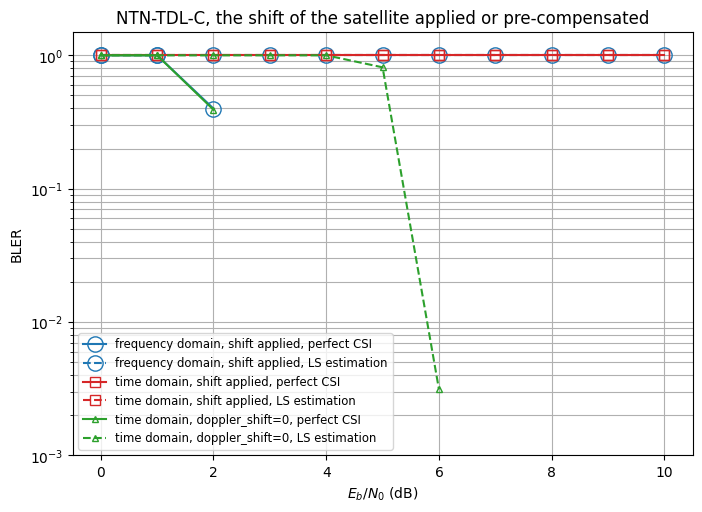

In [9]:
summary("s3")
plot("s3", "NTN-TDL-C, the shift of the satellite applied or pre-compensated",
     ["C0", "C0", "C3", "C3", "C2", "C2"],
     [("o", 11), ("o", 11), ("s", 7), ("s", 7), ("^", 5), ("^", 5)])

The receiver of this link has no frequency synchronization: nothing in it estimates or corrects a frequency offset, so the curves with the shift applied show the shift uncorrected. With the shift applied, perfect CSI in the frequency domain follows the phase of the shift from symbol to symbol: the BLER is 0.3984 at 2 dB, and no block has an error at 3 dB. LS estimation with the interpolation "nn" takes for every OFDM symbol the estimate of the nearest pilot symbol, while the phase of the shift turns by 0.7224 rad from symbol to symbol (section 2): in the frequency domain with the shift applied, its BLER stays at 1 up to 10 dB. In the time domain, the shift of 1.98 subcarrier spacings (section 2) moves the signal of every subcarrier onto other subcarriers within each OFDM symbol, the inter-carrier interference that the frequency domain does not model (`docs/model.md`, the bullet "Sampling of the shift"): the BLER stays at 1 up to 10 dB with perfect CSI and with LS estimation, with a BER of about 0.50, that of random bits. With `doppler_shift=0`, a link whose terminal pre-compensates the shift, the time domain gives with perfect CSI the BLER of the frequency domain, 0.3906 at 2 dB against 0.3984, and no error at 3 dB; with LS estimation its BLER is 0.8125 at 5 dB and 0.0031 at 6 dB, and no block has an error at 7 dB. The cyclic prefix of 44 samples is longer than the 42 taps of the discrete-time channel, so that the channel in the time domain causes no interference between the OFDM symbols. A link with the shift applied therefore needs the time domain; the frequency domain suits a link with `doppler_shift=0`, and with the shift applied it shows only the phase from symbol to symbol.

## 4. The block error rates of NTN-TDL-A to NTN-TDL-D

This section compares the four models in the frequency domain with `doppler_shift=0`, each with perfect CSI and with LS estimation: NTN-TDL-A and NTN-TDL-B with the NLOS delay spread of the dense urban scenario, NTN-TDL-C and NTN-TDL-D with its LOS delay spread and K-factor, which the cell of section 3 printed. The next cell first prints, for each model, its delay spread, the delay of its last path and the correlation of its frequency response at two frequencies the bandwidth of the grid apart, $|\sum_l P_l e^{-j 2 \pi W \tau_l}| / \sum_l P_l$ with the powers $P_l$ and the delays $\tau_l$ of its paths, the specular path included, and the bandwidth $W$, a measure of how flat the channel is over the grid. In the full mode, it then computes the curves and writes the results of sections 3 and 4 to `link_level_models_results.npz`.

In [10]:
sionna.phy.config.seed = seed

# How flat the channels of the link are over the grid: the correlation of the frequency
# response at two frequencies the bandwidth apart, from the delays and the powers of the
# paths, the specular path included
for model in "ABCD":
    los = model in ("C", "D")
    tdl = TDL(model, los_delay_spread if los else nlos_delay_spread, carrier_frequency,
              elevation_angle, satellite_height, k_factor=los_k_factor if los else None)
    delays = tdl.delays.cpu().numpy().astype(np.float64)
    powers = tdl.mean_powers.cpu().numpy().astype(np.float64)
    correlation = abs(np.sum(powers * np.exp(-2j * np.pi * rg.bandwidth * delays)))
    print(f"NTN-TDL-{model}: delay spread {float(tdl.delay_spread) * 1e9:.3f} ns, last "
          f"path at {delays.max() * 1e9:.1f} ns, correlation over "
          f"{rg.bandwidth / 1e6:.2f} MHz {correlation / np.sum(powers):.3f}")

S4_CURVES = [
    # label, model, domain, perfect CSI, doppler_shift
    (f"NTN-TDL-{model}, {'perfect CSI' if perfect_csi else 'LS estimation'}", model,
     "frequency", perfect_csi, 0.0) for model in "ABCD" for perfect_csi in (True, False)]
if mode is not None:
    results.update({f"s4_{key}": value for key, value in simulate(S4_CURVES).items()})
    # The version of Sionna from the metadata of its distribution: sionna-rt ships a
    # sionna/__init__.py of its own without __version__, and which of the two files an
    # installation keeps depends on the installer
    try:
        sionna_version = importlib.metadata.version("sionna")
    except importlib.metadata.PackageNotFoundError:
        sionna_version = importlib.metadata.version("sionna-no-rt")
    results.update({
        "seed": np.array(seed),
        # "0+unknown" when openntn is imported from a source tree that is not installed
        "openntn_version": np.array(openntn.__version__),
        "sionna_version": np.array(sionna_version),
        "torch_version": np.array(torch.__version__),
        "numpy_version": np.array(np.__version__),
        "date": np.array(datetime.datetime.now(datetime.timezone.utc).date().isoformat()),
        "device": np.array(str(device)),
        "precision": np.array(sionna.phy.config.precision),
        "scenario": np.array(scenario),
        "direction": np.array("downlink"),
        "carrier_frequency": np.array(carrier_frequency),
        "elevation_angle": np.array(elevation_angle),
        "satellite_height": np.array(satellite_height),
        "ut_speed": np.array(ut_speed),
        "los_delay_spread": np.array(los_delay_spread),
        "nlos_delay_spread": np.array(nlos_delay_spread),
        "los_k_factor": np.array(los_k_factor),
        "doppler_shift": np.array(TDL("C", los_delay_spread, carrier_frequency,
                                      elevation_angle, satellite_height).doppler_shift),
        "coded": np.array(True),
        "num_bits_per_symbol": np.array(num_bits_per_symbol),
        "coderate": np.array(coderate),
        "num_coded_bits": np.array(num_coded_bits),
        "num_information_bits": np.array(num_information_bits),
        "num_ofdm_symbols": np.array(num_ofdm_symbols),
        "fft_size": np.array(fft_size),
        "subcarrier_spacing": np.array(subcarrier_spacing),
        "cyclic_prefix_length": np.array(cyclic_prefix_length),
        "pilot_ofdm_symbol_indices": np.array(pilot_ofdm_symbol_indices),
        "l_min": np.array(l_min),
        "l_max": np.array(l_max),
        "batch_size": np.array(SIMS["batch_size"]),
        "max_mc_iter": np.array(SIMS["max_mc_iter"]),
        "num_target_block_errors": np.array(SIMS["num_target_block_errors"]),
        "run_time": np.array(time.time() - start),
    })
    print(f"Simulations of sections 3 and 4 took {results['run_time']:.1f} s")
    if mode == "full":
        np.savez(results_file, **results)
        print(f"Written to {results_file}")

NTN-TDL-A: delay spread 45.709 ns, last path at 129.9 ns, correlation over 9.36 MHz 0.496
NTN-TDL-B: delay spread 45.709 ns, last path at 262.3 ns, correlation over 9.36 MHz 0.529
NTN-TDL-C: delay spread 12.303 ns, last path at 140.3 ns, correlation over 9.36 MHz 0.989
NTN-TDL-D: delay spread 12.303 ns, last path at 93.7 ns, correlation over 9.36 MHz 0.988
NTN-TDL-A, perfect CSI
EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      0.0 | 2.1943e-01 | 1.0000e+00 |      105158 |      479232 |           64 |          64 |         5.0 |reached target block errors
      1.0 | 1.8237e-01 | 1.0000e+00 |       87399 |      479232 |           64 |          64 |         5.3 |reached target block errors
      2.0 | 8.6428e-02 | 8.9062e-01 |       41419 |      479232 |           57 |          6

BLER at 2, 3, 6 dB
  NTN-TDL-A, perfect CSI                           0.8906 (64 blocks); 0.3187 (160 blocks); 0.0125 (320 blocks)
  NTN-TDL-A, LS estimation                         1.0000 (64 blocks); 1.0000 (64 blocks); 0.4922 (128 blocks)
  NTN-TDL-B, perfect CSI                           0.8750 (64 blocks); 0.1875 (288 blocks); 0.0000 (320 blocks)
  NTN-TDL-B, LS estimation                         1.0000 (64 blocks); 1.0000 (64 blocks); 0.3125 (160 blocks)
  NTN-TDL-C, perfect CSI                           0.3688 (160 blocks); 0.0000 (320 blocks); not simulated
  NTN-TDL-C, LS estimation                         1.0000 (64 blocks); 1.0000 (64 blocks); 0.0000 (320 blocks)
  NTN-TDL-D, perfect CSI                           0.5312 (96 blocks); 0.0000 (320 blocks); not simulated
  NTN-TDL-D, LS estimation                         1.0000 (64 blocks); 1.0000 (64 blocks); 0.0094 (320 blocks)


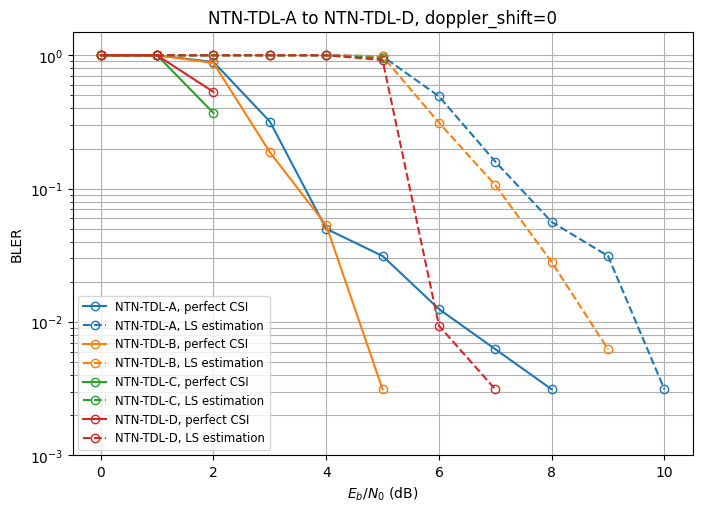

In [11]:
summary("s4")
plot("s4", "NTN-TDL-A to NTN-TDL-D, doppler_shift=0",
     ["C0", "C0", "C1", "C1", "C2", "C2", "C3", "C3"], [("o", 6)] * 8)

With perfect CSI, the LOS models NTN-TDL-C and NTN-TDL-D have no block error at 3 dB, where the NLOS models NTN-TDL-A and NTN-TDL-B have a BLER of 0.3187 and 0.1875; NTN-TDL-B has no error at 6 dB, NTN-TDL-A, with 0.0125 at 6 dB, only at 9 dB. The channel is normalized per batch example, so that the BLER follows how the channel varies over the subcarriers of a block, not its power. With the delay spread 12.303 ns and the K-factor 7.40 dB, the frequency responses of the LOS models at two frequencies 9.36 MHz apart, the bandwidth of the grid, have the correlation 0.989 and 0.988: they are nearly flat over the grid, and their curves fall as steeply as those of section 3. With the delay spread 45.709 ns, those of the NLOS models have the correlation 0.496 and 0.529: the code sees subcarriers of different strength in each block, and the BLER falls over several dB. LS estimation with the interpolation "nn" needs about 3 to 4 dB more than perfect CSI: NTN-TDL-C has no block error at 6 dB with LS estimation and at 3 dB with perfect CSI, and NTN-TDL-A has the BLER 0.05625 at 8 dB with LS estimation and 0.05 at 4 dB with perfect CSI.

## 5. The rank of the MIMO channel of the CDL

`CDL` takes the antenna arrays of the package. This section compares the channel of NTN-CDL-A to NTN-CDL-D with that of Sionna's TR 38.901 `CDL` with the same model letters, in the downlink at 2 GHz, with a UT of 1 x 2 and a satellite of 4 x 4 dual-polarized elements, 4 x 32 antennas: `AntennaArray(1, 2, "dual", "cross", "omni", 2e9)` at the UT and `AntennaArray(4, 4, "dual", "VH", "38.901", 2e9)` at the satellite, of the package for `CDL` and of Sionna, with the same arguments, for Sionna's `CDL`. `CDL` takes the satellite at 600 km seen at 50 degrees; both models take the delay spreads of sections 3 and 4 and double precision, and Sionna's `CDL` its other arguments at their defaults. The next cell computes the frequency response of each model on 72 subcarriers of 15 kHz for 64 examples, 16 in the reduced mode, in double precision, the singular values $s_1 \geq s_2 \geq s_3 \geq s_4$ of each of its 4 x 32 matrices and the ratios $s_i / s_1$, and prints their medians and the largest $s_3 / s_1$ of NTN-CDL-A to NTN-CDL-D.

In [12]:
sionna.phy.config.seed = seed

num_examples = 16 if mode == "reduced" else 64
mimo_frequencies = subcarrier_frequencies(72, 15e3, precision="double")
arrays = {
    "NTN-CDL": (AntennaArray(1, 2, "dual", "cross", "omni", 2e9, precision="double"),
                AntennaArray(4, 4, "dual", "VH", "38.901", 2e9, precision="double")),
    "CDL": (SionnaAntennaArray(1, 2, "dual", "cross", "omni", 2e9, precision="double"),
            SionnaAntennaArray(4, 4, "dual", "VH", "38.901", 2e9, precision="double")),
}


def singular_value_ratios(model):
    """The ratios s_i / s_1 of the channel matrices of all examples and subcarriers"""
    a, tau = model(batch_size=num_examples, num_time_steps=1, sampling_frequency=1.0)
    h = cir_to_ofdm_channel(mimo_frequencies, a, tau)
    # [examples, subcarriers, UT antennas, satellite antennas]
    h = h[:, 0, :, 0, :, 0, :].permute(0, 3, 1, 2)
    s = torch.linalg.svdvals(h)
    return (s / s[..., :1]).reshape(-1, s.shape[-1]).cpu().numpy()


ratios = {}
for name in "ABCD":
    delay_spread = los_delay_spread if name in ("C", "D") else nlos_delay_spread
    ut_array, bs_array = arrays["NTN-CDL"]
    ratios[f"NTN-CDL-{name}"] = singular_value_ratios(
        CDL(name, delay_spread, 2e9, 50.0, 600e3, ut_array=ut_array, bs_array=bs_array,
            precision="double"))
    ut_array, bs_array = arrays["CDL"]
    ratios[f"CDL-{name}"] = singular_value_ratios(
        SionnaCDL(name, delay_spread, 2e9, ut_array=ut_array, bs_array=bs_array,
                  precision="double"))

print(f"{num_examples} examples x 72 subcarriers; medians of s_i / s_1, i = 1 to 4")
for label, r in ratios.items():
    print(f"  {label:>9}: " + "  ".join(f"{v:.3e}" for v in np.median(r, axis=0)))
largest = max(float(ratios[f"NTN-CDL-{name}"][:, 2].max()) for name in "ABCD")
print(f"Largest s_3 / s_1 of NTN-CDL-A to NTN-CDL-D: {largest:.3e}")

64 examples x 72 subcarriers; medians of s_i / s_1, i = 1 to 4
  NTN-CDL-A: 1.000e+00  5.415e-01  2.625e-16  9.284e-17
      CDL-A: 1.000e+00  5.766e-01  1.150e-01  6.554e-02
  NTN-CDL-B: 1.000e+00  5.753e-01  2.534e-16  9.725e-17
      CDL-B: 1.000e+00  7.119e-01  4.709e-01  3.241e-01
  NTN-CDL-C: 1.000e+00  7.914e-01  3.052e-16  7.191e-17
      CDL-C: 1.000e+00  6.689e-01  4.117e-01  2.382e-01
  NTN-CDL-D: 1.000e+00  6.618e-01  2.711e-16  8.100e-17
      CDL-D: 1.000e+00  8.445e-01  9.010e-02  6.356e-02
Largest s_3 / s_1 of NTN-CDL-A to NTN-CDL-D: 9.805e-16


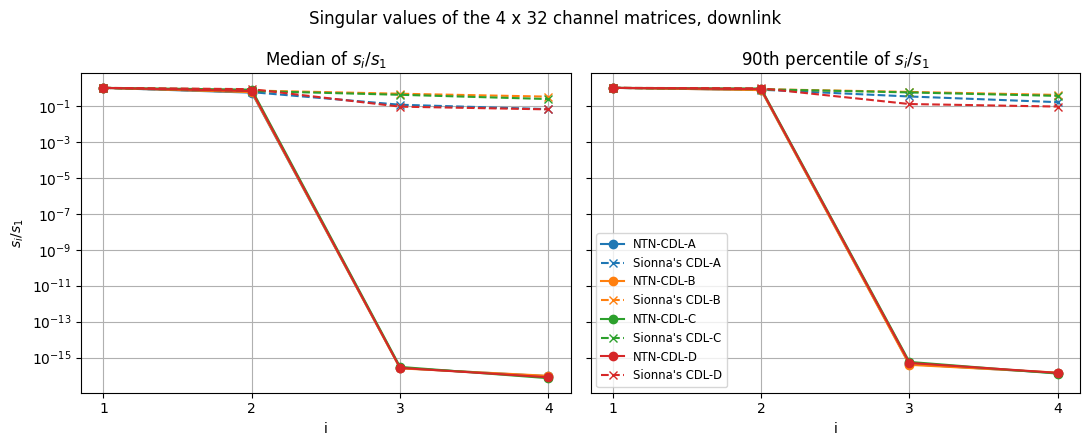

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
index = np.arange(1, 5)
for ax, (statistic, title) in zip(axes, ((50, "Median"), (90, "90th percentile"))):
    for k, name in enumerate("ABCD"):
        ax.semilogy(index, np.percentile(ratios[f"NTN-CDL-{name}"], statistic, axis=0),
                    color=f"C{k}", marker="o", label=f"NTN-CDL-{name}")
        ax.semilogy(index, np.percentile(ratios[f"CDL-{name}"], statistic, axis=0),
                    color=f"C{k}", marker="x", linestyle="--",
                    label=f"Sionna's CDL-{name}")
    ax.set_xticks(index)
    ax.set_xlabel("i")
    ax.set_title(f"{title} of $s_i / s_1$")
    ax.grid(True, which="both")
axes[0].set_ylabel("$s_i / s_1$")
axes[1].legend(fontsize="small")
fig.suptitle("Singular values of the 4 x 32 channel matrices, downlink")
fig.tight_layout()
plt.show()

For each of NTN-CDL-A to NTN-CDL-D, $s_3/s_1$ and $s_4/s_1$ are of the order of the rounding error of double precision, $s_3/s_1$ at most 9.805e-16 in this run: the 4 x 32 channel of every subcarrier and example has two singular values that are not zero, and its rank is 2. Sionna's CDL-A to CDL-D have four singular values that are not zero, the rank of a channel with 4 antennas at the UT. All rays of the NTN-CDL models leave the satellite in one direction: their angular spreads of departure are zero, and all clusters leave the satellite at the same angles (`docs/model.md`, the bullets "NTN-CDL models", "Doppler shift of the satellite" and "Antennas"). The response of the array of the satellite is then the same for every ray, for each of the two polarizations of its elements, so that the channel has at most the rank of the two polarizations, whatever the number of antennas. Sionna's CDL has spreads of the angles of departure at the base station, and its rays leave it in different directions. A MIMO link over the NTN-CDL models can thus carry at most two streams, one per polarization.